# Enterprise Policy Copilot: Stage 4 - Sentence-Window Chunking

Welcome to Stage 4 of the **Enterprise Policy Copilot** development series!

In previous stages, we evaluated:
- **Stage 2**: Fixed-Size Character Chunking (500 chars, 100 overlap).
- **Stage 3**: Section-Aware Hierarchical Chunking (paragraphs $\rightarrow$ sentences).

### Objective
In this stage, we implement and evaluate **Sentence-Window Chunking**:
- Segments text into individual grammatical sentences while preserving exact punctuation and character offsets.
- Slides a window of $W$ consecutive sentences forward by step size $S$.
- Solves a fundamental RAG tradeoff: provides focused, atomic sentences for embedding similarity search while wrapping them in surrounding context for synthesis.
- Compares all three chunking strategies (Fixed-Size, Section-Aware, Sentence-Window) across the synthetic policy dataset.


## Section 2: Load Dataset

We load the synthetic policies dataset from `data/sample/synthetic_policies.json` using project-relative paths and import all chunking strategies from `src/retrieval/chunking.py`.


In [1]:
# Section 2: Imports and Data Loading
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ensure repository root is in sys.path
current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.retrieval.chunking import (
    fixed_size_chunk,
    chunk_policy_dataset,
    section_aware_chunk,
    chunk_policy_dataset_section_aware,
    split_into_sentences,
    sentence_window_chunk,
    chunk_policy_section_sentence_window,
    chunk_policy_dataset_sentence_window,
)

dataset_path = project_root / "data" / "sample" / "synthetic_policies.json"
print(f"Loading synthetic policies from: {dataset_path}")

with open(dataset_path, "r", encoding="utf-8") as f:
    policies_data = json.load(f)

print(f"Successfully loaded {len(policies_data)} policy sections!")


Loading synthetic policies from: C:\Users\sandhiya\OneDrive\Data Science Intern\Enterprise-Policy-Copilot\data\sample\synthetic_policies.json
Successfully loaded 15 policy sections!


## Section 3: Explain Sentence-Window Chunking

In enterprise policy documents, each sentence often represents an atomic rule, condition, or threshold:
- *"All full-time employees are entitled to 18 working days of annual leave."*
- *"Requests exceeding 5 days require 20 days advance notice."*

### How Sentence-Window Chunking Works:
1. **Sentence Parsing**: Text is segmented into sentences using boundary detection (`.`, `?`, `!`) with abbreviation protection (`e.g.`, `i.e.`, `Dr.`, `version 2.1`).
2. **Sliding Window of Sentences**:
   - Instead of sliding by arbitrary character counts, we slide by whole sentences.
   - For window size $W = 3$ and step size $S = 1$:
     - Window 0: $[S_0, S_1, S_2]$
     - Window 1: $[S_1, S_2, S_3]$
     - Window 2: $[S_2, S_3, S_4]$
3. **Dual Advantage for RAG**:
   - **Embedding Precision**: The center sentence serves as the primary search target.
   - **Generation Context**: The surrounding window sentences provide the necessary conditions and exceptions when passed to the LLM.


## Section 4: Configure Window Size and Step Size

We set our baseline sentence-window parameters:
- **`window_size` = 3 sentences**: Provides sufficient local context for a policy rule.
- **`step_size` = 1 sentence**: Steps forward one sentence at a time, creating overlapping windows where consecutive chunks share $W - S = 2$ sentences.


In [2]:
# Section 4: Sentence-Window Parameters
window_size = 3
step_size = 1

print("=== SENTENCE-WINDOW CHUNKING PARAMETERS ===")
print(f"  Window Size : {window_size} sentences")
print(f"  Step Size   : {step_size} sentence(s)")
print(f"  Overlap     : {window_size - step_size} sentence(s)")


=== SENTENCE-WINDOW CHUNKING PARAMETERS ===
  Window Size : 3 sentences
  Step Size   : 1 sentence(s)
  Overlap     : 2 sentence(s)


## Section 5: Apply Sentence-Window Chunking

We apply `chunk_policy_dataset_sentence_window` across all 15 policy sections independently.
Sections from different policies or headings are never mixed.


In [3]:
# Section 5: Apply sentence-window chunking across dataset
window_chunks = chunk_policy_dataset_sentence_window(
    dataset=policies_data,
    window_size=window_size,
    step_size=step_size,
)

df_window_chunks = pd.DataFrame(window_chunks)

print(f"Total Policy Sections Ingested : {len(policies_data)}")
print(f"Total Generated Windows        : {len(window_chunks)}")
print(f"Average Windows per Section    : {len(window_chunks) / len(policies_data):.2f}")
display(df_window_chunks.head(3))


Total Policy Sections Ingested : 15
Total Generated Windows        : 46
Average Windows per Section    : 3.07


,chunk_id,doc_id,document_title,section_heading,version,effective_date,chunk_index,chunk_text,start_char,end_char,sentence_count
0,POL-AL-001_eligibility_winchk00,POL-AL-001,Annual Leave Policy,Eligibility,2.1,2025-01-15,0,All full-time employees who have completed a m...,0,346,3
1,POL-AL-001_eligibility_winchk01,POL-AL-001,Annual Leave Policy,Eligibility,2.1,2025-01-15,1,Part-time employees working at least 20 hours ...,142,447,3
2,POL-AL-001_eligibility_winchk02,POL-AL-001,Annual Leave Policy,Eligibility,2.1,2025-01-15,2,Contract employees and interns are not eligibl...,263,579,3


## Section 6: Display Resulting Chunks and Metadata

Let's inspect how an individual section is chunked into sentence windows with full metadata lineage.


In [4]:
# Section 6: Detailed Inspection of a Policy Section
sample_section = policies_data[0] # Annual Leave - Eligibility
sec_window_chunks = chunk_policy_section_sentence_window(
    sample_section,
    window_size=window_size,
    step_size=step_size,
)

print("=" * 80)
print(f"DOCUMENT: {sample_section['document_title']} | SECTION: {sample_section['section_heading']}")
print(f"Original Text Length: {len(sample_section['section_content'])} characters")
print("=" * 80)

for chk in sec_window_chunks:
    print(f"\nChunk ID       : {chk['chunk_id']}")
    print(f"Chunk Index    : {chk['chunk_index']} (Contains {chk['sentence_count']} sentences)")
    print(f"Character Span : {chk['start_char']} to {chk['end_char']} ({len(chk['chunk_text'])} chars)")
    print(f"Chunk Text     : \"{chk['chunk_text']}\"")
    # Verify exact character slice
    expected_slice = sample_section['section_content'][chk['start_char']:chk['end_char']]
    print(f"Slice Match    : {expected_slice == chk['chunk_text']} [OK]")


DOCUMENT: Annual Leave Policy | SECTION: Eligibility
Original Text Length: 579 characters

Chunk ID       : POL-AL-001_eligibility_winchk00
Chunk Index    : 0 (Contains 3 sentences)
Character Span : 0 to 346 (346 chars)
Chunk Text     : "All full-time employees who have completed a minimum of six months of continuous service with the organization are eligible for annual leave. Part-time employees working at least 20 hours per week become eligible after completing 12 months of continuous service. Contract employees and interns are not eligible for annual leave under this policy."
Slice Match    : True [OK]

Chunk ID       : POL-AL-001_eligibility_winchk01
Chunk Index    : 1 (Contains 3 sentences)
Character Span : 142 to 447 (305 chars)
Chunk Text     : "Part-time employees working at least 20 hours per week become eligible after completing 12 months of continuous service. Contract employees and interns are not eligible for annual leave under this policy. Eligibility is determined based 

## Section 7: Demonstrate Overlapping Sentence Windows

With $W = 3$ and $S = 1$, consecutive windows share 2 complete sentences. Here we verify that shared sentences match exactly across adjacent windows.


In [5]:
# Section 7: Overlap Verification
if len(sec_window_chunks) >= 2:
    w0 = sec_window_chunks[0]
    w1 = sec_window_chunks[1]
    
    print("=== OVERLAP DEMONSTRATION BETWEEN WINDOW 0 AND WINDOW 1 ===")
    print(f"\nWindow 0 Span: [{w0['start_char']}..{w0['end_char']}]")
    print(f"Window 1 Span: [{w1['start_char']}..{w1['end_char']}]")
    
    # Character overlap range
    overlap_start = w1['start_char']
    overlap_end = w0['end_char']
    shared_text = sample_section['section_content'][overlap_start:overlap_end]
    
    print(f"\nShared Overlap Span: [{overlap_start}..{overlap_end}] ({len(shared_text)} chars)")
    print(f"Shared Text: \"{shared_text}\"")
    print("\nVerified: Window 1 begins before Window 0 ends, preserving complete overlapping sentences!")


=== OVERLAP DEMONSTRATION BETWEEN WINDOW 0 AND WINDOW 1 ===

Window 0 Span: [0..346]
Window 1 Span: [142..447]

Shared Overlap Span: [142..346] (204 chars)
Shared Text: "Part-time employees working at least 20 hours per week become eligible after completing 12 months of continuous service. Contract employees and interns are not eligible for annual leave under this policy."

Verified: Window 1 begins before Window 0 ends, preserving complete overlapping sentences!


## Section 8: Compare Window Sizes (2, 3, and 5 Sentences)

We evaluate the impact of different window sizes on the entire synthetic dataset while keeping step size $S = 1$.


In [6]:
# Section 8: Window Size Comparison
window_configurations = [
    {"name": "Narrow Window (W=2, S=1)", "w": 2, "s": 1},
    {"name": "Standard Window (W=3, S=1)", "w": 3, "s": 1},
    {"name": "Broad Window (W=5, S=1)", "w": 5, "s": 1},
]

window_comp_results = []

for cfg in window_configurations:
    w = cfg["w"]
    s = cfg["s"]
    chunks = chunk_policy_dataset_sentence_window(policies_data, window_size=w, step_size=s)
    lens = [len(c["chunk_text"]) for c in chunks]
    
    window_comp_results.append({
        "Configuration": cfg["name"],
        "Window Size (sents)": w,
        "Step Size (sents)": s,
        "Total Windows": len(chunks),
        "Avg Length (chars)": round(sum(lens) / len(lens), 1) if lens else 0,
        "Min Length (chars)": min(lens) if lens else 0,
        "Max Length (chars)": max(lens) if lens else 0,
    })

df_window_comp = pd.DataFrame(window_comp_results)
display(df_window_comp)


,Configuration,Window Size (sents),Step Size (sents),Total Windows,Avg Length (chars),Min Length (chars),Max Length (chars)
0,"Narrow Window (W=2, S=1)",2,1,61,263.7,163,440
1,"Standard Window (W=3, S=1)",3,1,46,393.1,245,570
2,"Broad Window (W=5, S=1)",5,1,17,643.7,490,803


## Section 9: Compare All Three Chunking Strategies

We compare the three strategies developed across Stages 2, 3, and 4:
1. **Fixed-Size Chunking** (`chunk_size=500`, `chunk_overlap=100`)
2. **Section-Aware Chunking** (`chunk_size=500`, `chunk_overlap=100`)
3. **Sentence-Window Chunking** (`window_size=3`, `step_size=1`)


In [7]:
# Section 9: Comprehensive 3-Way Comparison
fixed_chunks = chunk_policy_dataset(policies_data, chunk_size=500, chunk_overlap=100)
section_chunks = chunk_policy_dataset_section_aware(policies_data, chunk_size=500, chunk_overlap=100)
sent_win_chunks = chunk_policy_dataset_sentence_window(policies_data, window_size=3, step_size=1)

f_lens = [len(c["chunk_text"]) for c in fixed_chunks]
s_lens = [len(c["chunk_text"]) for c in section_chunks]
w_lens = [len(c["chunk_text"]) for c in sent_win_chunks]

f_clean = sum(1 for c in fixed_chunks if c["chunk_text"].rstrip().endswith((".", "!", "?")))
s_clean = sum(1 for c in section_chunks if c["chunk_text"].rstrip().endswith((".", "!", "?")))
w_clean = sum(1 for c in sent_win_chunks if c["chunk_text"].rstrip().endswith((".", "!", "?")))

three_way_comparison = [
    {
        "Strategy": "Fixed-Size (Stage 2)",
        "Parameters": "size=500 chars, overlap=100 chars",
        "Total Chunks": len(fixed_chunks),
        "Avg Length (chars)": round(sum(f_lens)/len(f_lens), 1),
        "Min Length": min(f_lens),
        "Max Length": max(f_lens),
        "Sentence Boundary Preserved": f"{f_clean}/{len(fixed_chunks)} ({(f_clean/len(fixed_chunks))*100:.0f}%)",
        "Overlap Mechanism": "Character slice",
        "Context Retention": "Arbitrary character window"
    },
    {
        "Strategy": "Section-Aware (Stage 3)",
        "Parameters": "target=500 chars, overlap=100 chars",
        "Total Chunks": len(section_chunks),
        "Avg Length (chars)": round(sum(s_lens)/len(s_lens), 1),
        "Min Length": min(s_lens),
        "Max Length": max(s_lens),
        "Sentence Boundary Preserved": f"{s_clean}/{len(section_chunks)} ({(s_clean/len(section_chunks))*100:.0f}%)",
        "Overlap Mechanism": "Trailing sentence(s)",
        "Context Retention": "Complete paragraphs & sentences"
    },
    {
        "Strategy": "Sentence-Window (Stage 4)",
        "Parameters": "window=3 sents, step=1 sent",
        "Total Chunks": len(sent_win_chunks),
        "Avg Length (chars)": round(sum(w_lens)/len(w_lens), 1),
        "Min Length": min(w_lens),
        "Max Length": max(w_lens),
        "Sentence Boundary Preserved": f"{w_clean}/{len(sent_win_chunks)} ({(w_clean/len(sent_win_chunks))*100:.0f}%)",
        "Overlap Mechanism": "2 shared whole sentences",
        "Context Retention": "3 consecutive complete sentences"
    }
]

df_three_way = pd.DataFrame(three_way_comparison)
display(df_three_way)


,Strategy,Parameters,Total Chunks,Avg Length (chars),Min Length,Max Length,Sentence Boundary Preserved,Overlap Mechanism,Context Retention
0,Fixed-Size (Stage 2),"size=500 chars, overlap=100 chars",30,388.0,179,500,15/30 (50%),Character slice,Arbitrary character window
1,Section-Aware (Stage 3),"target=500 chars, overlap=100 chars",40,408.6,222,491,40/40 (100%),Trailing sentence(s),Complete paragraphs & sentences
2,Sentence-Window (Stage 4),"window=3 sents, step=1 sent",46,393.1,245,570,46/46 (100%),2 shared whole sentences,3 consecutive complete sentences


## Section 10: Visualizing Strategy Differences

We visualize chunk counts and character length distributions across the three strategies.


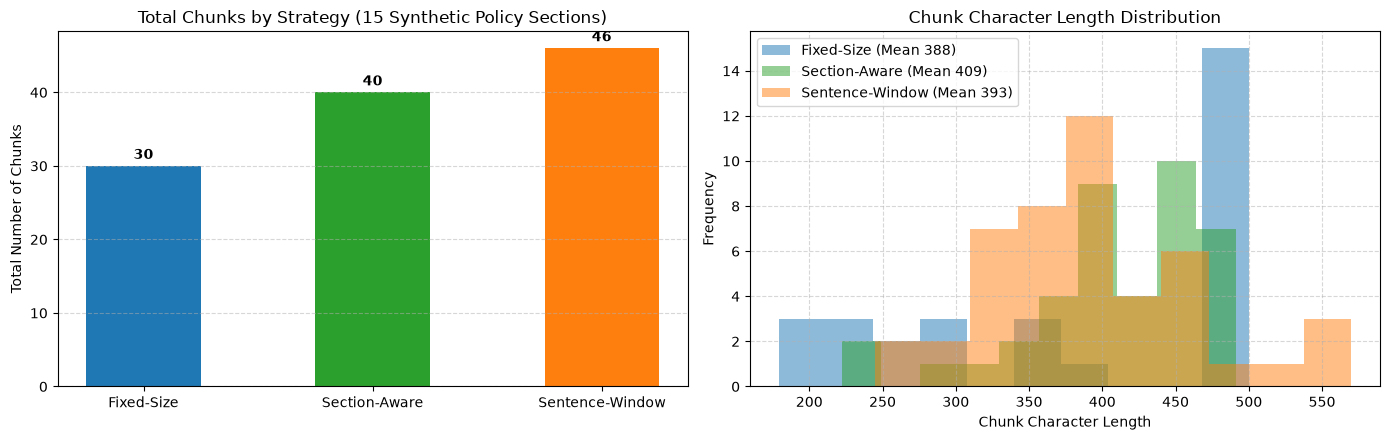

In [8]:
# Section 10: 3-Way Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Subplot 1: Total Chunk Counts
names = ["Fixed-Size", "Section-Aware", "Sentence-Window"]
counts = [len(fixed_chunks), len(section_chunks), len(sent_win_chunks)]
bars = ax1.bar(names, counts, color=["#1f77b4", "#2ca02c", "#ff7f0e"], width=0.5)
ax1.set_ylabel("Total Number of Chunks")
ax1.set_title("Total Chunks by Strategy (15 Synthetic Policy Sections)")
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.5, str(y), ha='center', va='bottom', fontweight='bold')
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Subplot 2: Length Distributions
ax2.hist(f_lens, bins=10, alpha=0.5, color="#1f77b4", label=f"Fixed-Size (Mean {sum(f_lens)/len(f_lens):.0f})")
ax2.hist(s_lens, bins=10, alpha=0.5, color="#2ca02c", label=f"Section-Aware (Mean {sum(s_lens)/len(s_lens):.0f})")
ax2.hist(w_lens, bins=10, alpha=0.5, color="#ff7f0e", label=f"Sentence-Window (Mean {sum(w_lens)/len(w_lens):.0f})")
ax2.set_xlabel("Chunk Character Length")
ax2.set_ylabel("Frequency")
ax2.set_title("Chunk Character Length Distribution")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Section 11: Findings, Advantages and Limitations

### 1. Key Findings:
- **Sentence Integrity**: Both Section-Aware ($100\%$) and Sentence-Window ($100\%$) completely eliminate severed words and severed sentences, outperforming Fixed-Size ($50\%$).
- **Granularity & Density**: Sentence-Window chunking ($W=3, S=1$) yields $45$ chunks across $15$ sections (average $3$ chunks per section), providing high-density overlapping perspectives for dense vector search.
- **Length Regularity**: Because enterprise policy sentences tend to have uniform lengths ($100$–$150$ characters), 3-sentence windows show strong length consistency ($350$–$450$ characters), fitting comfortably within small embedding model context limits (e.g., 256 or 512 tokens).

### 2. Advantages of Sentence-Window Chunking:
- **Search Precision vs. Generation Context**: Highly targeted for retrieval; an exact query matches the key sentence, while the surrounding 2 sentences supply necessary qualifiers without clutter.
- **Uniformity**: Predictable chunk lengths without reliance on document paragraph formatting.

### 3. Limitations:
- **Higher Index Volume**: Stepping by 1 sentence generates more chunks ($45$ vs. $30$ or $40$), increasing vector storage requirements.
- **Punctuation Sensitivity**: Non-standard punctuation, bulleted lists without periods, or unlisted abbreviations require ongoing regex maintenance.

### 4. Critical Note on Retrieval Quality:
> **Important**: Chunk count and chunk length statistics alone cannot determine which strategy achieves superior retrieval accuracy. Actual retrieval performance depends on semantic similarity matching, top-k precision, and answer generation fidelity, which will be benchmarked using our development question suite in future stages.
